In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

from matplotlib.colors import LogNorm

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"
EXTERNAL_DATA_DIR = DATA_DIR / "external"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
REPORTS_DIR = OUTPUT_DIR / "reports"

DATA_PATH = RAW_DATA_DIR / "yellow_tripdata_2026-03.parquet"

ZONE_MAP_PATH = EXTERNAL_DATA_DIR / "taxi_zones.shp"
ZONE_LOOKUP_PATH = EXTERNAL_DATA_DIR / "taxi_zone_lookup.csv"

for directory in [
    PROCESSED_DATA_DIR,
    FIGURES_DIR,
    TABLES_DIR,
    REPORTS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("Zone shapefile exists:", ZONE_MAP_PATH.exists())
print("Zone lookup exists:", ZONE_LOOKUP_PATH.exists())

Project root: C:\Users\User\Desktop\NYC-TLC-Yellow-Taxi\NYC-TLC-Yellow-Taxi-main
Dataset path: C:\Users\User\Desktop\NYC-TLC-Yellow-Taxi\NYC-TLC-Yellow-Taxi-main\data\raw\yellow_tripdata_2026-03.parquet
Dataset exists: True
Zone shapefile exists: True
Zone lookup exists: True


In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

df = pd.read_parquet(DATA_PATH)

print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {len(df):,}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())

Dataset shape: (3952451, 20)
Number of rows: 3,952,451
Number of columns: 20


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-03-01 00:02:26,2026-03-01 00:13:45,1.0,2.58,1.0,N,48,151,1,14.2,1.0,0.5,4.99,0.0,1.0,24.94,2.5,0.0,0.75
1,2,2026-03-01 00:19:33,2026-03-01 00:28:21,1.0,1.50,1.0,N,238,166,1,10.0,1.0,0.5,0.00,0.0,1.0,15.00,2.5,0.0,0.00
2,2,2026-03-01 00:07:20,2026-03-01 00:15:12,2.0,0.88,1.0,N,90,249,1,8.6,1.0,0.5,2.87,0.0,1.0,17.22,2.5,0.0,0.75
3,2,2026-03-01 00:16:11,2026-03-01 00:28:20,1.0,1.76,1.0,N,249,137,1,12.1,1.0,0.5,3.57,0.0,1.0,21.42,2.5,0.0,0.75
4,2,2026-03-01 00:20:47,2026-03-01 00:30:44,2.0,1.57,1.0,N,100,142,1,11.4,1.0,0.5,3.43,0.0,1.0,20.58,2.5,0.0,0.75


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3952451 entries, 0 to 3952450
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [5]:
dataset_structure = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "missing_count": df.isna().sum().values,
    "missing_percent": (
        df.isna().mean().mul(100).round(2).values
    ),
    "unique_values": df.nunique().values
})

display(dataset_structure)

,column,data_type,missing_count,missing_percent,unique_values
0,VendorID,int32,0,0.00,4
1,tpep_pickup_datetime,datetime64[us],0,0.00,1819531
2,tpep_dropoff_datetime,datetime64[us],0,0.00,1818904
3,passenger_count,float64,945748,23.93,8
4,trip_distance,float64,0,0.00,4817
5,RatecodeID,float64,945748,23.93,7
6,store_and_fwd_flag,object,945748,23.93,2
7,PULocationID,int32,0,0.00,261
8,DOLocationID,int32,0,0.00,260
9,payment_type,int64,0,0.00,5


In [6]:
dataset_structure.to_csv(
    TABLES_DIR / "raw_dataset_structure.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Initial dataset structure saved.")

Initial dataset structure saved.


In [7]:
START_DATE = pd.Timestamp("2026-03-01")
END_DATE = pd.Timestamp("2026-04-01")

march_mask = (
    df["tpep_pickup_datetime"].ge(START_DATE)
    & df["tpep_pickup_datetime"].lt(END_DATE)
)

df_mar = df.loc[march_mask].copy()

print(f"Original rows: {len(df):,}")
print(f"March rows: {len(df_mar):,}")
print(f"Excluded rows: {len(df) - len(df_mar):,}")

Original rows: 3,952,451
March rows: 3,952,432
Excluded rows: 19


In [8]:
print("Pickup datetime range:")
print(df_mar["tpep_pickup_datetime"].min())
print(df_mar["tpep_pickup_datetime"].max())

print("\nDropoff datetime range:")
print(df_mar["tpep_dropoff_datetime"].min())
print(df_mar["tpep_dropoff_datetime"].max())

print("\nNumber of records:", f"{len(df_mar):,}")
print("Number of columns:", df_mar.shape[1])

Pickup datetime range:
2026-03-01 00:00:00
2026-03-31 23:59:59

Dropoff datetime range:
2026-03-01 00:01:05
2026-04-02 16:03:47

Number of records: 3,952,432
Number of columns: 20


In [9]:
outside_march = (
    df_mar["tpep_pickup_datetime"].lt(START_DATE)
    | df_mar["tpep_pickup_datetime"].ge(END_DATE)
)

print("Records outside March:", int(outside_march.sum()))

assert len(df_mar) > 0, "Filtered dataset is empty."
assert outside_march.sum() == 0, "Out-of-range records detected."

print("Date filter validation passed.")

Records outside March: 0
Date filter validation passed.


In [10]:
dataset_overview = pd.DataFrame({
    "item": [
        "dataset_name",
        "source",
        "source_file",
        "analysis_period",
        "filtering_variable",
        "number_of_records",
        "number_of_columns",
        "exact_duplicate_rows"
    ],
    "value": [
        "NYC TLC Yellow Taxi Trip Records",
        "NYC Taxi and Limousine Commission",
        DATA_PATH.name,
        "2026-03-01 to 2026-03-31",
        "tpep_pickup_datetime",
        len(df_mar),
        df_mar.shape[1],
        int(df_mar.duplicated().sum())
    ]
})

display(dataset_overview)

,item,value
0,dataset_name,NYC TLC Yellow Taxi Trip Records
1,source,NYC Taxi and Limousine Commission
2,source_file,yellow_tripdata_2026-03.parquet
3,analysis_period,2026-03-01 to 2026-03-31
4,filtering_variable,tpep_pickup_datetime
5,number_of_records,3952432
6,number_of_columns,20
7,exact_duplicate_rows,0


In [11]:
dataset_overview.to_csv(
    TABLES_DIR / "dataset_overview_march_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset overview saved.")

Dataset overview saved.


In [12]:
data_dictionary = pd.DataFrame({
    "column": df_mar.columns,
    "data_type": df_mar.dtypes.astype(str).values,
    "missing_count": df_mar.isna().sum().values,
    "missing_percent": (
        df_mar.isna().mean().mul(100).round(2).values
    ),
    "unique_values": df_mar.nunique().values
})

display(data_dictionary)

,column,data_type,missing_count,missing_percent,unique_values
0,VendorID,int32,0,0.00,4
1,tpep_pickup_datetime,datetime64[us],0,0.00,1819512
2,tpep_dropoff_datetime,datetime64[us],0,0.00,1818890
3,passenger_count,float64,945748,23.93,8
4,trip_distance,float64,0,0.00,4817
5,RatecodeID,float64,945748,23.93,7
6,store_and_fwd_flag,object,945748,23.93,2
7,PULocationID,int32,0,0.00,261
8,DOLocationID,int32,0,0.00,260
9,payment_type,int64,0,0.00,5


In [13]:
data_dictionary.to_csv(
    TABLES_DIR / "data_dictionary_march_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Data dictionary saved.")

Data dictionary saved.


In [14]:
missing_summary = pd.DataFrame({
    "missing_count": df_mar.isna().sum(),
    "missing_percent": (
        df_mar.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percent
passenger_count,945748,23.93
congestion_surcharge,945748,23.93
store_and_fwd_flag,945748,23.93
RatecodeID,945748,23.93
Airport_fee,945748,23.93
tpep_dropoff_datetime,0,0.00
VendorID,0,0.00
tpep_pickup_datetime,0,0.00
DOLocationID,0,0.00
payment_type,0,0.00


In [15]:
duplicate_count = df_mar.duplicated().sum()

print(f"Exact duplicate rows: {duplicate_count:,}")
print(
    "Duplicate percentage:",
    round(duplicate_count / len(df_mar) * 100, 4),
    "%"
)

Exact duplicate rows: 0
Duplicate percentage: 0.0 %


In [16]:
missing_cols = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "Airport_fee"
]

missing_pattern = df_mar[missing_cols].isna()

missing_per_row = missing_pattern.sum(axis=1)

missing_pattern_summary = (
    missing_per_row
    .value_counts()
    .sort_index()
    .rename_axis("missing_columns_per_row")
    .to_frame("row_count")
)

display(missing_pattern_summary)

all_five_missing = missing_pattern.all(axis=1)

print(
    "Rows with all five columns missing:",
    f"{all_five_missing.sum():,}"
)

,row_count
missing_columns_per_row,
0,3006684
5,945748


Rows with all five columns missing: 945,748


In [17]:
print("Payment type among rows with all five values missing:")

display(
    df_mar.loc[all_five_missing, "payment_type"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("payment_type")
    .to_frame("row_count")
)

Payment type among rows with all five values missing:


,row_count
payment_type,
0,945748


In [18]:
df_mar["trip_duration_min"] = (
    df_mar["tpep_dropoff_datetime"]
    - df_mar["tpep_pickup_datetime"]
).dt.total_seconds() / 60

print("Trip duration calculated.")
display(df_mar["trip_duration_min"].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
).to_frame("trip_duration_min"))

Trip duration calculated.


,trip_duration_min
count,3.952432e+06
mean,1.729016e+01
std,2.487705e+01
min,-1.866667e+02
1%,0.000000e+00
5%,3.250000e+00
50%,1.328333e+01
95%,4.466667e+01
99%,7.525000e+01
max,7.620600e+03


In [19]:
duration_checks = {
    "missing_pickup_time":
        df_mar["tpep_pickup_datetime"].isna().sum(),

    "missing_dropoff_time":
        df_mar["tpep_dropoff_datetime"].isna().sum(),

    "negative_duration":
        (df_mar["trip_duration_min"] < 0).sum(),

    "zero_duration":
        (df_mar["trip_duration_min"] == 0).sum(),

    "duration_over_4_hours":
        (df_mar["trip_duration_min"] > 240).sum()
}

display(
    pd.Series(
        duration_checks,
        name="record_count"
    ).to_frame()
)

,record_count
missing_pickup_time,0
missing_dropoff_time,0
negative_duration,2
zero_duration,49131
duration_over_4_hours,956


In [20]:
negative_duration = df_mar.loc[
    df_mar["trip_duration_min"] < 0,
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "fare_amount",
        "total_amount",
        "payment_type"
    ]
]

display(negative_duration)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,fare_amount,total_amount,payment_type
3023527,2026-03-01 11:34:00,2026-03-01 11:18:00,6.55,3.0,29.74,0
3752016,2026-03-23 21:09:57,2026-03-23 18:03:17,3.20,3.0,0.00,0


In [21]:
long_duration = (
    df_mar.loc[
        df_mar["trip_duration_min"] > 240,
        [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "trip_distance",
            "fare_amount",
            "total_amount",
            "payment_type",
            "trip_duration_min"
        ]
    ]
    .sort_values("trip_duration_min", ascending=False)
)

display(long_duration.head(15))

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,fare_amount,total_amount,payment_type,trip_duration_min
1680839,2026-03-18 09:09:52,2026-03-23 16:10:28,0.00,3.00,4.50,2,7620.600000
399880,2026-03-05 11:27:09,2026-03-10 16:09:13,0.07,21.20,22.70,2,7482.066667
2481525,2026-03-26 13:09:41,2026-03-31 17:05:21,2.47,45.70,47.20,2,7435.666667
2164051,2026-03-23 01:44:03,2026-03-27 18:10:59,18.50,70.20,74.70,2,6746.933333
3643919,2026-03-20 20:45:18,2026-03-25 08:42:38,3.80,13.25,23.00,0,6477.333333
1471162,2026-03-16 01:59:29,2026-03-19 18:11:15,15.93,70.00,76.75,2,5291.766667
2865430,2026-03-30 14:01:54,2026-04-02 16:03:47,12.40,60.40,63.90,2,4441.883333
1987042,2026-03-20 23:26:16,2026-03-23 14:59:59,1.88,28.72,33.47,2,3813.716667
1558176,2026-03-17 00:17:33,2026-03-19 12:38:38,9.15,35.90,48.65,2,3621.083333
3375375,2026-03-12 20:01:30,2026-03-15 00:00:45,0.78,9.76,13.76,0,3119.250000


In [22]:
quality_checks = {
    "negative_distance":
        (df_mar["trip_distance"] < 0).sum(),

    "zero_distance":
        (df_mar["trip_distance"] == 0).sum(),

    "negative_fare":
        (df_mar["fare_amount"] < 0).sum(),

    "zero_fare":
        (df_mar["fare_amount"] == 0).sum(),

    "negative_tip":
        (df_mar["tip_amount"] < 0).sum(),

    "negative_tolls":
        (df_mar["tolls_amount"] < 0).sum(),

    "negative_total_amount":
        (df_mar["total_amount"] < 0).sum(),

    "zero_total_amount":
        (df_mar["total_amount"] == 0).sum()
}

quality_summary = pd.DataFrame({
    "check": list(quality_checks.keys()),
    "record_count": list(quality_checks.values())
})

quality_summary["percent_of_trips"] = (
    quality_summary["record_count"] / len(df_mar) * 100
)

quality_summary["percent_of_trips"] = (
    quality_summary["percent_of_trips"].round(3)
)

display(quality_summary)

,check,record_count,percent_of_trips
0,negative_distance,0,0.000
1,zero_distance,121209,3.067
2,negative_fare,20724,0.524
3,zero_fare,2995,0.076
4,negative_tip,40,0.001
5,negative_tolls,1582,0.040
6,negative_total_amount,21305,0.539
7,zero_total_amount,584,0.015


In [23]:
negative_amounts = df_mar.loc[
    (df_mar["fare_amount"] < 0)
    | (df_mar["total_amount"] < 0)
].copy()

payment_quality = (
    negative_amounts
    .groupby("payment_type")
    .agg(
        record_count=("payment_type", "size"),
        negative_fare_count=(
            "fare_amount",
            lambda x: (x < 0).sum()
        ),
        negative_total_count=(
            "total_amount",
            lambda x: (x < 0).sum()
        )
    )
    .reset_index()
)

payment_quality["share_percent"] = (
    payment_quality["record_count"]
    / max(len(negative_amounts), 1)
    * 100
).round(2)

display(payment_quality)

,payment_type,record_count,negative_fare_count,negative_total_count,share_percent
0,0,22,19,10,0.10
1,1,266,262,266,1.25
2,2,5377,4791,5377,25.22
3,3,2205,2205,2205,10.34
4,4,13447,13447,13447,63.08


In [24]:
missing_summary.to_csv(
    TABLES_DIR / "missing_values_march_2026.csv",
    encoding="utf-8-sig"
)

quality_summary.to_csv(
    TABLES_DIR / "data_quality_summary_march_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

payment_quality.to_csv(
    TABLES_DIR / "negative_amounts_by_payment_type.csv",
    index=False,
    encoding="utf-8-sig"
)

cleaning_rules = pd.DataFrame([
    {
        "issue": "Missing timestamps",
        "decision": "Report and investigate",
        "reason": "Timestamps are required for temporal analysis"
    },
    {
        "issue": "Exact duplicate rows",
        "decision": "Do not remove automatically",
        "reason": "No duplicates were observed in the previous analysis"
    },
    {
        "issue": "Negative trip duration",
        "decision": "Flag for investigation",
        "reason": "May indicate inconsistent timestamps"
    },
    {
        "issue": "Zero duration or distance",
        "decision": "Retain and investigate",
        "reason": "Not necessarily invalid without further evidence"
    },
    {
        "issue": "Negative fare or total amount",
        "decision": "Retain and investigate",
        "reason": "Could represent adjustments or other payment-related cases"
    },
    {
        "issue": "Missing values in five columns",
        "decision": "Do not impute automatically",
        "reason": "Investigate the shared missingness pattern first"
    }
])

cleaning_rules.to_csv(
    TABLES_DIR / "cleaning_decisions_march_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Quality reports saved successfully.")

Quality reports saved successfully.


In [25]:
numeric_cols = [
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "tolls_amount",
    "passenger_count",
    "trip_duration_min"
]

numeric_cols = [
    col for col in numeric_cols
    if col in df_mar.columns
]

print("Variables for descriptive analysis:")
print(numeric_cols)

Variables for descriptive analysis:
['trip_distance', 'fare_amount', 'tip_amount', 'total_amount', 'tolls_amount', 'passenger_count', 'trip_duration_min']


In [26]:
descriptive_stats = (
    df_mar[numeric_cols]
    .describe(
        percentiles=[
            0.01, 0.25, 0.50, 0.75, 0.95, 0.99
        ]
    )
    .T
)

descriptive_stats["missing_count"] = (
    df_mar[numeric_cols].isna().sum()
)

descriptive_stats["zero_count"] = (
    df_mar[numeric_cols].eq(0).sum()
)

descriptive_stats["negative_count"] = (
    df_mar[numeric_cols].lt(0).sum()
)

display(descriptive_stats.round(2))

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,missing_count,zero_count,negative_count
trip_distance,3952432.0,5.98,581.06,0.00,0.00,1.01,1.82,3.71,12.70,19.58,288381.68,0,121209,0
fare_amount,3952432.0,21.33,18.69,-990.00,3.00,10.00,15.60,26.80,60.40,81.40,1843.30,0,2995,20724
tip_amount,3952432.0,2.86,3.91,-75.75,0.00,0.00,2.11,3.95,10.19,17.44,397.00,0,1510682,40
total_amount,3952432.0,30.10,22.41,-1022.46,8.01,17.22,23.40,34.90,77.48,105.50,1850.55,0,584,21305
tolls_amount,3952432.0,0.53,2.29,-111.79,0.00,0.00,0.00,0.00,7.46,7.46,1400.00,0,3689838,1582
passenger_count,3006684.0,1.23,0.63,0.00,1.00,1.00,1.00,1.00,2.00,4.00,8.00,945748,12967,0
trip_duration_min,3952432.0,17.29,24.88,-186.67,0.00,7.98,13.28,21.23,44.67,75.25,7620.60,0,49131,2


In [27]:
descriptive_stats.to_csv(
    TABLES_DIR / "numeric_descriptive_statistics_march_2026.csv",
    encoding="utf-8-sig"
)

print("Descriptive statistics saved.")

Descriptive statistics saved.


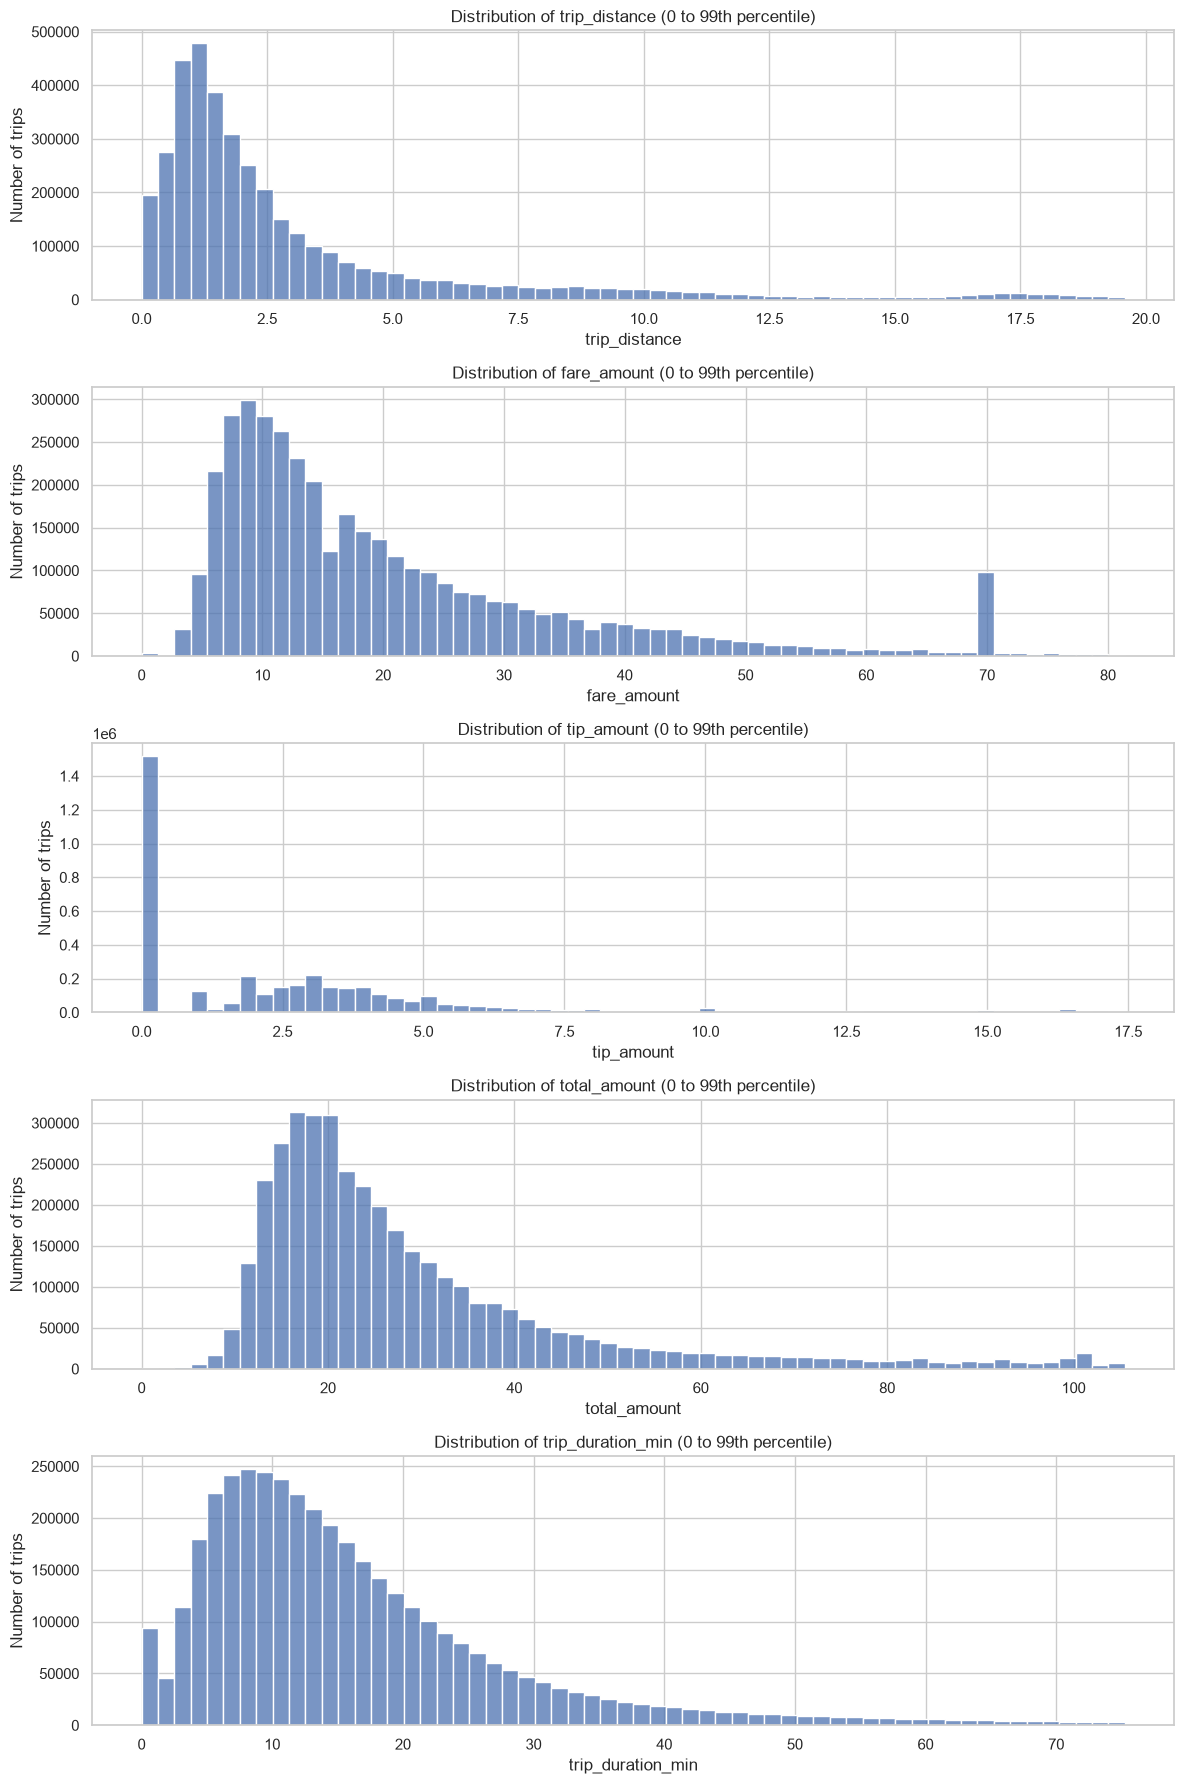

In [28]:
plot_cols = [
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "trip_duration_min"
]

fig, axes = plt.subplots(
    nrows=len(plot_cols),
    ncols=1,
    figsize=(12, 18)
)

for ax, col in zip(axes, plot_cols):
    series = df_mar[col].dropna()

    upper_limit = series.quantile(0.99)

    plot_data = series[
        (series >= 0) &
        (series <= upper_limit)
    ]

    sns.histplot(
        data=plot_data,
        bins=60,
        ax=ax
    )

    ax.set_title(
        f"Distribution of {col} (0 to 99th percentile)"
    )
    ax.set_xlabel(col)
    ax.set_ylabel("Number of trips")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "numeric_distributions_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [29]:
passenger_counts = (
    df_mar["passenger_count"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("passenger_count")
    .to_frame("trip_count")
)

passenger_counts["share_percent"] = (
    passenger_counts["trip_count"]
    / len(df_mar)
    * 100
).round(2)

display(passenger_counts)

,trip_count,share_percent
passenger_count,,
0.0,12967,0.33
1.0,2504910,63.38
2.0,351152,8.88
3.0,75897,1.92
4.0,48148,1.22
5.0,8481,0.21
6.0,5126,0.13
8.0,3,0.00
NaN,945748,23.93


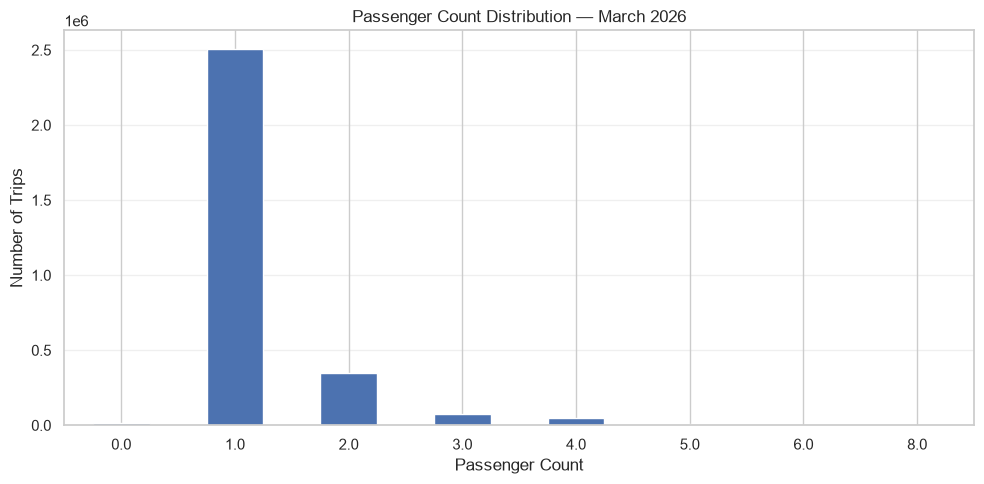

In [30]:
passenger_plot_data = (
    df_mar["passenger_count"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 5))

passenger_plot_data.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Passenger Count Distribution — March 2026")
ax.set_xlabel("Passenger Count")
ax.set_ylabel("Number of Trips")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "passenger_count_distribution_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [31]:
eda_cols = [
    "trip_distance",
    "fare_amount",
    "trip_duration_min"
]

upper_limits = df_mar[eda_cols].quantile(0.99)

valid_mask = (
    df_mar[eda_cols].notna().all(axis=1)
    & (df_mar[eda_cols] > 0).all(axis=1)
    & (df_mar[eda_cols] <= upper_limits).all(axis=1)
)

eda_data = df_mar.loc[valid_mask, eda_cols].copy()

print("Original March records:", f"{len(df_mar):,}")
print("Records selected for multivariate analysis:", f"{len(eda_data):,}")
print("Excluded from this analysis:", f"{len(df_mar) - len(eda_data):,}")

display(eda_data.describe().round(2))

Original March records: 3,952,432
Records selected for multivariate analysis: 3,674,109
Excluded from this analysis: 278,323


,trip_distance,fare_amount,trip_duration_min
count,3674109.00,3674109.00,3674109.00
mean,3.17,20.05,16.21
std,3.53,14.67,11.70
min,0.01,0.01,0.02
25%,1.08,10.00,8.15
50%,1.85,14.90,13.20
75%,3.60,25.40,20.70
max,19.58,81.40,75.25


In [32]:
eda_sample = eda_data.sample(
    n=min(30_000, len(eda_data)),
    random_state=42
)

print("Scatter plot sample size:", f"{len(eda_sample):,}")

Scatter plot sample size: 30,000


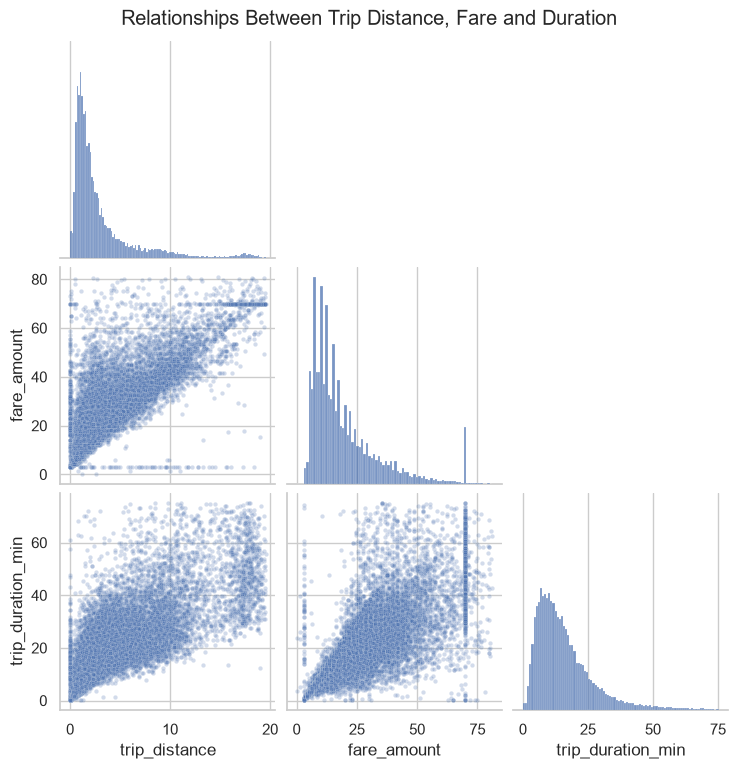

In [33]:
pair_plot = sns.pairplot(
    eda_sample,
    vars=[
        "trip_distance",
        "fare_amount",
        "trip_duration_min"
    ],
    corner=True,
    plot_kws={
        "alpha": 0.25,
        "s": 10
    }
)

pair_plot.fig.suptitle(
    "Relationships Between Trip Distance, Fare and Duration",
    y=1.02
)

pair_plot.fig.savefig(
    FIGURES_DIR / "multivariate_pairplot_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [34]:
pearson_corr = eda_data.corr(
    method="pearson"
)

display(pearson_corr.round(3))

pearson_corr.to_csv(
    TABLES_DIR / "pearson_correlation_march_2026.csv",
    encoding="utf-8-sig"
)

,trip_distance,fare_amount,trip_duration_min
trip_distance,1.000,0.862,0.785
fare_amount,0.862,1.000,0.796
trip_duration_min,0.785,0.796,1.000


In [35]:
spearman_corr = eda_data.corr(
    method="spearman"
)

display(spearman_corr.round(3))

spearman_corr.to_csv(
    TABLES_DIR / "spearman_correlation_march_2026.csv",
    encoding="utf-8-sig"
)

,trip_distance,fare_amount,trip_duration_min
trip_distance,1.000,0.862,0.840
fare_amount,0.862,1.000,0.888
trip_duration_min,0.840,0.888,1.000


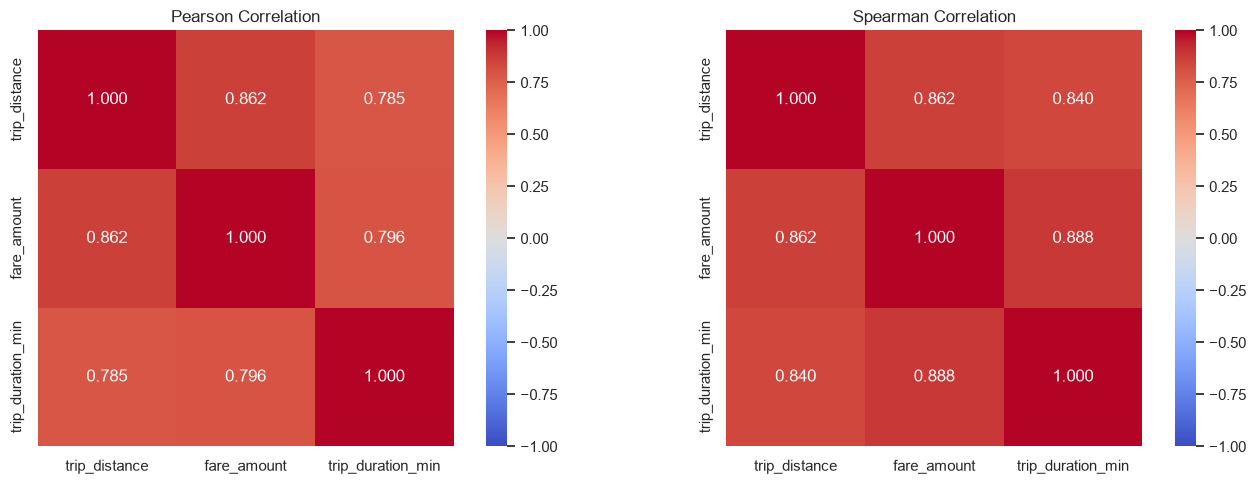

In [36]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Pearson Correlation")

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Spearman Correlation")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "correlation_heatmaps_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [37]:
pairs = [
    ("trip_distance", "fare_amount"),
    ("trip_distance", "trip_duration_min"),
    ("fare_amount", "trip_duration_min")
]

correlation_comparison = pd.DataFrame([
    {
        "variable_1": var1,
        "variable_2": var2,
        "pearson": pearson_corr.loc[var1, var2],
        "spearman": spearman_corr.loc[var1, var2]
    }
    for var1, var2 in pairs
])

display(correlation_comparison.round(3))

correlation_comparison.to_csv(
    TABLES_DIR / "correlation_comparison_march_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

,variable_1,variable_2,pearson,spearman
0,trip_distance,fare_amount,0.862,0.862
1,trip_distance,trip_duration_min,0.785,0.840
2,fare_amount,trip_duration_min,0.796,0.888


In [38]:
daily_demand = (
    df_mar
    .set_index("tpep_pickup_datetime")
    .resample("D")
    .size()
    .rename("trip_count")
    .asfreq("D")
)

print("Number of days:", len(daily_demand))
print("Missing days:", daily_demand.isna().sum())
print(
    "Date range:",
    daily_demand.index.min(),
    "to",
    daily_demand.index.max()
)

display(daily_demand.describe().to_frame())

Number of days: 31
Missing days: 0
Date range: 2026-03-01 00:00:00 to 2026-03-31 00:00:00


,trip_count
count,31.000000
mean,127497.806452
std,14885.198889
min,101370.000000
25%,114991.500000
50%,127830.000000
75%,135342.000000
max,161051.000000


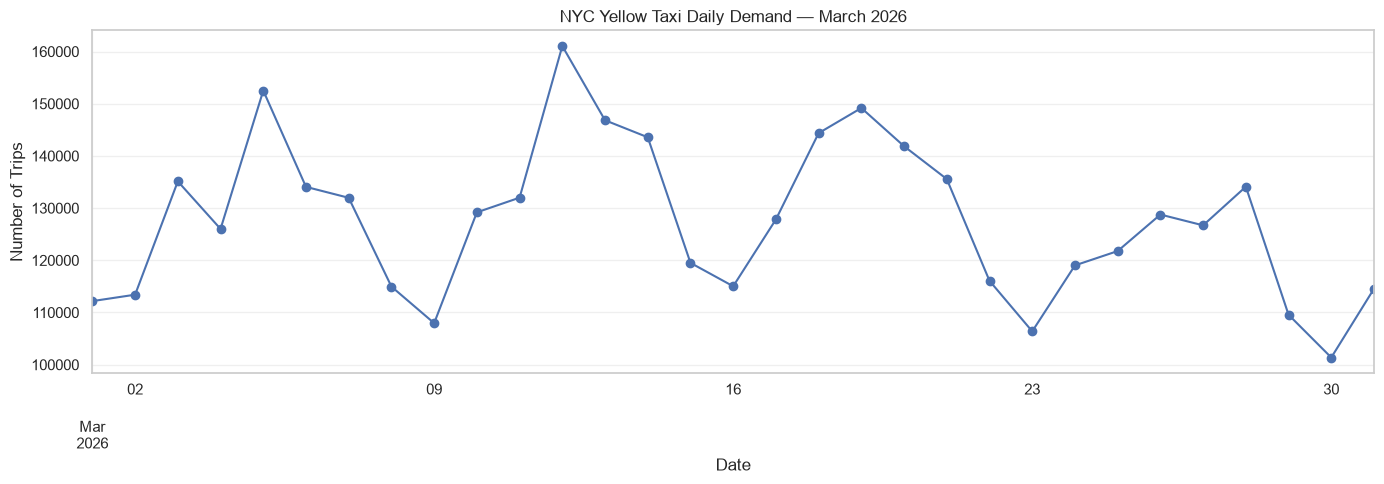

In [39]:
fig, ax = plt.subplots(figsize=(14, 5))

daily_demand.plot(
    ax=ax,
    marker="o",
    linewidth=1.5
)

ax.set_title("NYC Yellow Taxi Daily Demand — March 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Trips")
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "daily_demand_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [40]:
print("Top 5 highest-demand days:")
display(
    daily_demand.nlargest(5)
    .rename_axis("date")
    .to_frame()
)

print("Top 5 lowest-demand days:")
display(
    daily_demand.nsmallest(5)
    .rename_axis("date")
    .to_frame()
)

Top 5 highest-demand days:


,trip_count
date,
2026-03-12,161051
2026-03-05,152515
2026-03-19,149180
2026-03-13,146830
2026-03-18,144364


Top 5 lowest-demand days:


,trip_count
date,
2026-03-30,101370
2026-03-23,106383
2026-03-09,107953
2026-03-29,109562
2026-03-01,112181


In [41]:
weekday_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_summary = (
    daily_demand.to_frame()
    .assign(day_of_week=lambda x: x.index.dayofweek)
    .groupby("day_of_week")["trip_count"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reindex(range(7))
)

weekday_summary.index = weekday_names

display(weekday_summary.round(2))

,count,mean,median,std,min,max
Monday,5,108827.40,107953.0,5516.34,101370,115023
Tuesday,5,125144.20,127830.0,8258.02,114554,135124
Wednesday,4,131034.50,129003.0,9827.47,121768,144364
Thursday,4,147877.75,150847.5,13687.36,128765,161051
Friday,4,137362.00,137961.5,8840.54,126695,146830
Saturday,4,136301.50,134830.5,5065.07,131974,143571
Sunday,5,114454.20,114960.0,3789.75,109562,119504


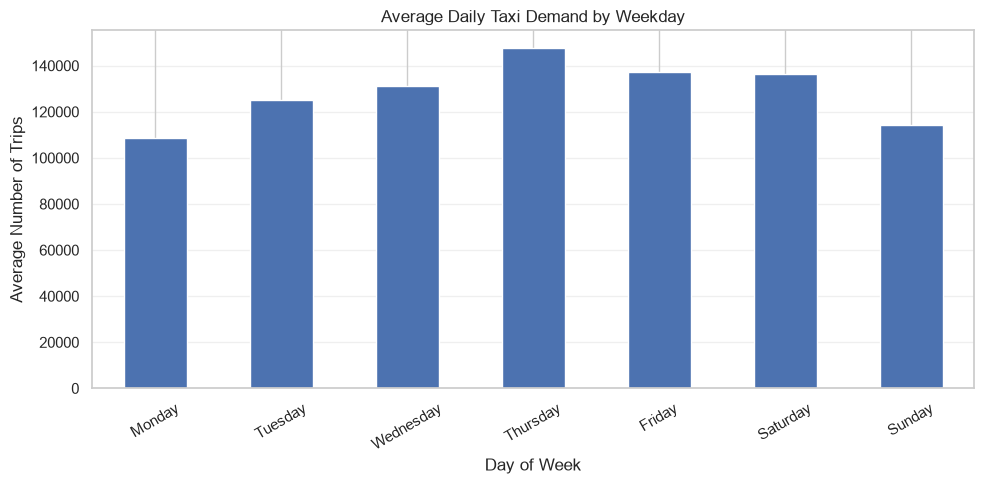

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))

weekday_summary["mean"].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Average Daily Taxi Demand by Weekday")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average Number of Trips")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "weekday_demand_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [43]:
hourly_demand = (
    df_mar
    .groupby(df_mar["tpep_pickup_datetime"].dt.hour)
    .size()
    .reindex(range(24), fill_value=0)
    .rename("trip_count")
    .to_frame()
)

hourly_demand.index.name = "pickup_hour"

hourly_demand["share_percent"] = (
    hourly_demand["trip_count"]
    / len(df_mar)
    * 100
)

display(
    hourly_demand
    .sort_values("trip_count", ascending=False)
    .head(10)
    .round(2)
)

,trip_count,share_percent
pickup_hour,,
18,279487,7.07
17,263040,6.66
19,255817,6.47
21,246449,6.24
20,241164,6.10
16,229824,5.81
15,222287,5.62
22,215215,5.45
14,212513,5.38


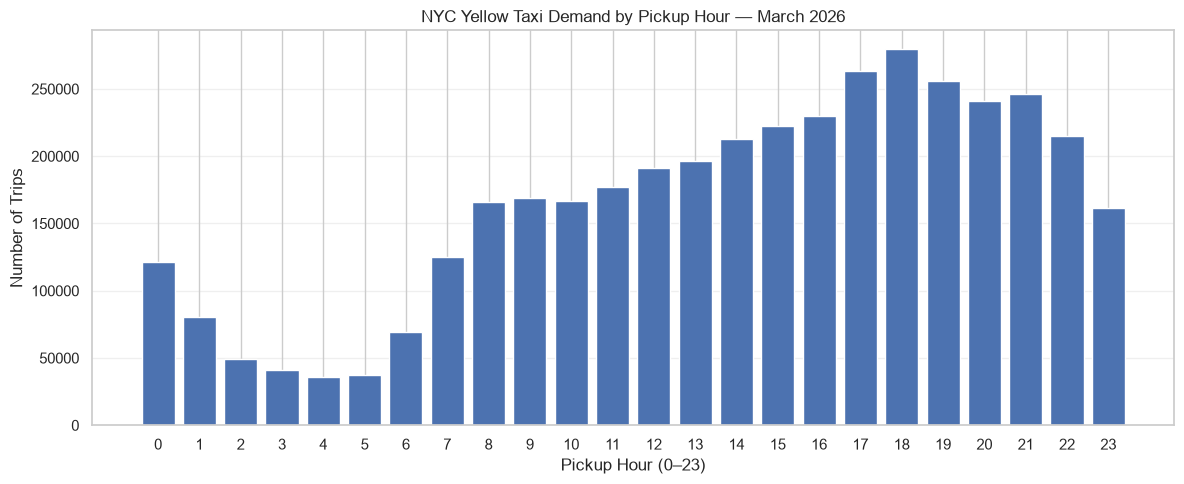

In [44]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    hourly_demand.index,
    hourly_demand["trip_count"]
)

ax.set_title("NYC Yellow Taxi Demand by Pickup Hour — March 2026")
ax.set_xlabel("Pickup Hour (0–23)")
ax.set_ylabel("Number of Trips")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "hourly_demand_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [45]:
df_mar["day_of_week"] = (
    df_mar["tpep_pickup_datetime"].dt.dayofweek
)

df_mar["pickup_hour"] = (
    df_mar["tpep_pickup_datetime"].dt.hour
)

hourly_weekday_demand = (
    df_mar
    .pivot_table(
        index="day_of_week",
        columns="pickup_hour",
        aggfunc="size",
        fill_value=0
    )
    .reindex(
        index=range(7),
        columns=range(24),
        fill_value=0
    )
)

hourly_weekday_demand.index = weekday_names

display(hourly_weekday_demand)

pickup_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Monday,8173,4365,2508,1890,3041,6165,13460,25322,31783,27928,26006,26119,27947,27767,30600,32464,34368,42946,40573,33583,31584,31309,22634,11602
Tuesday,6969,3353,2097,1422,2041,4963,12111,24701,33115,31650,28275,28693,30690,30923,34356,36361,37571,45062,47424,42610,43036,45401,33913,18984
Wednesday,8325,3859,2084,1436,2211,4597,10218,20806,28180,27004,23543,24280,25501,25960,28142,29489,29812,35049,38179,35654,36745,37791,28638,16635
Thursday,9349,4642,2322,1649,2549,5072,11142,22200,29886,27701,24806,25498,26932,27812,31019,33606,34678,40146,44226,40224,39226,41601,38375,26850
Friday,16767,8308,4705,3310,3951,5326,9977,17414,21768,21005,21379,22490,25051,25418,29805,31831,31925,36786,40962,37902,32198,32915,34640,33615
Saturday,29530,22184,16457,11651,8061,4043,4971,6494,10109,15236,18874,22083,24693,26432,26032,26593,29151,31250,35411,36520,31942,32241,35832,39416
Sunday,42510,33575,19365,19654,13792,6994,7250,8017,11365,18052,24006,27786,30088,31885,32559,31943,32319,31801,32712,29324,26433,25191,21183,14467


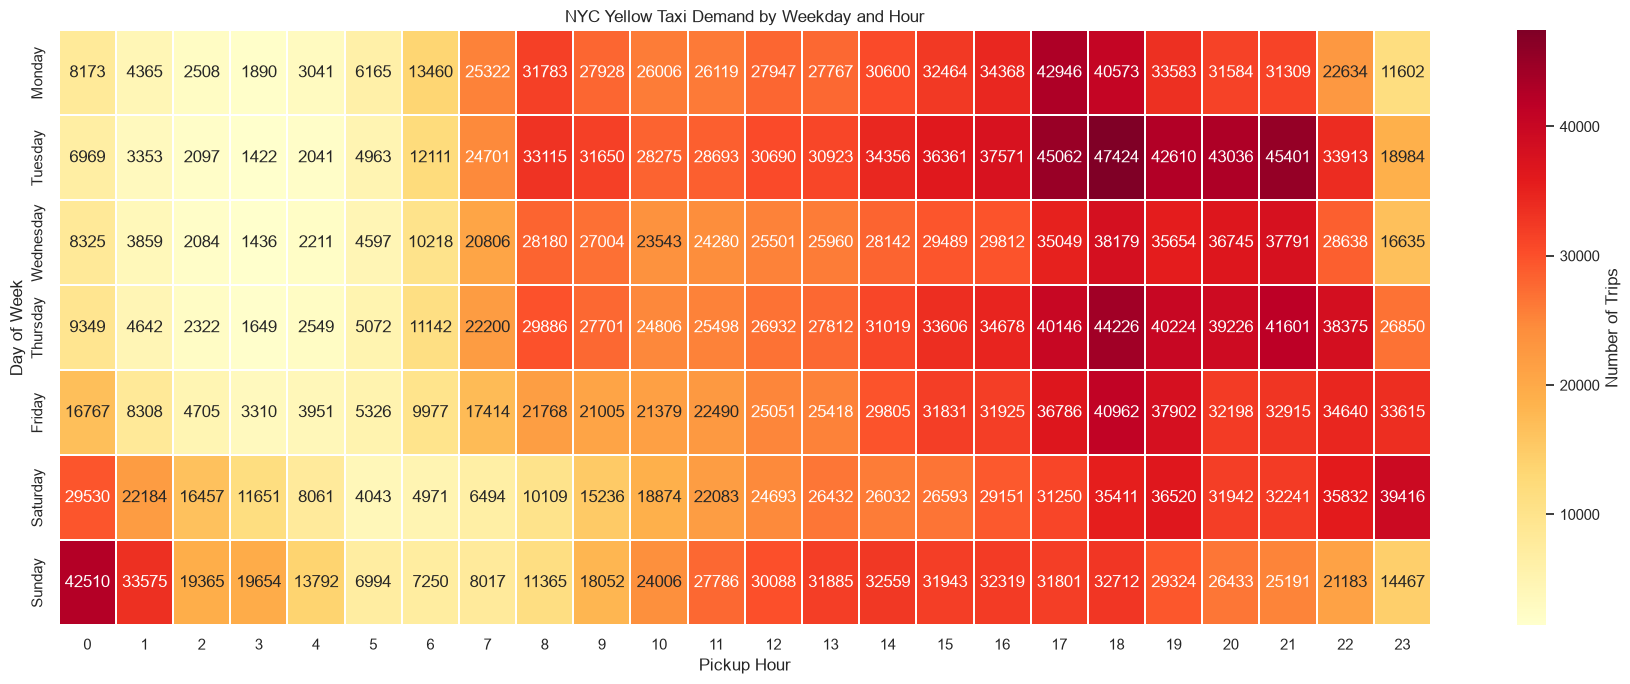

In [46]:
fig, ax = plt.subplots(figsize=(18, 7))

sns.heatmap(
    hourly_weekday_demand,
    cmap="YlOrRd",
    linewidths=0.3,
    annot=True,
    fmt=".0f",
    linecolor="white",
    cbar_kws={"label": "Number of Trips"},
    ax=ax
)

ax.set_xlabel("Pickup Hour")
ax.set_ylabel("Day of Week")
ax.set_title("NYC Yellow Taxi Demand by Weekday and Hour")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "weekday_hour_demand_march_2026.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [47]:
daily_demand.rename_axis("date").to_csv(
    TABLES_DIR / "daily_demand_march_2026.csv",
    encoding="utf-8-sig"
)

weekday_summary.to_csv(
    TABLES_DIR / "weekday_demand_march_2026.csv",
    encoding="utf-8-sig"
)

hourly_demand.to_csv(
    TABLES_DIR / "hourly_demand_march_2026.csv",
    encoding="utf-8-sig"
)

hourly_weekday_demand.to_csv(
    TABLES_DIR / "weekday_hour_demand_march_2026.csv",
    encoding="utf-8-sig"
)

print("Temporal analysis tables saved successfully.")

Temporal analysis tables saved successfully.


In [48]:
zones_geo = gpd.read_file(ZONE_MAP_PATH)
zones_lookup = pd.read_csv(ZONE_LOOKUP_PATH)

print("Geographic data shape:", zones_geo.shape)
print("Zone lookup shape:", zones_lookup.shape)

print("\nGeographic columns:")
print(zones_geo.columns.tolist())

print("\nLookup columns:")
print(zones_lookup.columns.tolist())

print("\nCoordinate reference system:")
print(zones_geo.crs)

display(zones_geo.head())
display(zones_lookup.head())

Geographic data shape: (263, 7)
Zone lookup shape: (265, 4)

Geographic columns:
['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']

Lookup columns:
['LocationID', 'Borough', 'Zone', 'service_zone']

Coordinate reference system:
EPSG:2263


,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [49]:

print("Missing LocationID in shapefile:",
      zones_geo["LocationID"].isna().sum())

print("Duplicate LocationID in shapefile:",
      zones_geo["LocationID"].duplicated().sum())

print("Missing LocationID in lookup:",
      zones_lookup["LocationID"].isna().sum())

print("Duplicate LocationID in lookup:",
      zones_lookup["LocationID"].duplicated().sum())

print("\nMissing geometries:",
      zones_geo.geometry.isna().sum())

print("Empty geometries:",
      zones_geo.geometry.is_empty.sum())

print("\nNumber of unique geographic zones:",
      zones_geo["LocationID"].nunique())

print("Number of unique lookup zones:",
      zones_lookup["LocationID"].nunique())

Missing LocationID in shapefile: 0
Duplicate LocationID in shapefile: 0
Missing LocationID in lookup: 0
Duplicate LocationID in lookup: 0

Missing geometries: 0
Empty geometries: 0

Number of unique geographic zones: 263
Number of unique lookup zones: 265


In [50]:
pickup_counts = (
    df_mar
    .groupby("PULocationID")
    .size()
    .rename("trip_count")
    .reset_index()
    .rename(columns={"PULocationID": "LocationID"})
)

pickup_counts["LocationID"] = pickup_counts["LocationID"].astype("int64")

print("Number of zones with pickup activity:",
      pickup_counts["LocationID"].nunique())

print("Total trips counted:", pickup_counts["trip_count"].sum())

display(pickup_counts.head())

Number of zones with pickup activity: 261
Total trips counted: 3952432


,LocationID,trip_count
0,1,527
1,2,11
2,3,500
3,4,15595
4,5,2


In [51]:
zones_geo["LocationID"] = zones_geo["LocationID"].astype("int64")
zones_lookup["LocationID"] = zones_lookup["LocationID"].astype("int64")

zones_demand = zones_geo.merge(
    pickup_counts,
    on="LocationID",
    how="left",
    validate="one_to_one"
)

zones_demand["trip_count"] = (
    zones_demand["trip_count"]
    .fillna(0)
    .astype("int64")
)

print("Merged geographic data shape:", zones_demand.shape)
print("Zones with zero recorded pickups:",
      (zones_demand["trip_count"] == 0).sum())

display(
    zones_demand[
        ["LocationID", "zone", "borough", "trip_count"]
    ].head()
)

Merged geographic data shape: (263, 8)
Zones with zero recorded pickups: 4


,LocationID,zone,borough,trip_count
0,1,Newark Airport,EWR,527
1,2,Jamaica Bay,Queens,11
2,3,Allerton/Pelham Gardens,Bronx,500
3,4,Alphabet City,Manhattan,15595
4,5,Arden Heights,Staten Island,2


In [52]:
top_pickup_zones = (
    pickup_counts
    .merge(
        zones_lookup[["LocationID", "Zone", "Borough"]],
        on="LocationID",
        how="left",
        validate="one_to_one"
    )
    .sort_values("trip_count", ascending=False)
    .reset_index(drop=True)
)

top_pickup_zones["share_percent"] = (
    top_pickup_zones["trip_count"]
    / len(df_mar)
    * 100
)

top_pickup_zones.to_csv(
    TABLES_DIR / "top_pickup_zones_march_2026.csv",
    index=False
)

display(top_pickup_zones.head(15))

,LocationID,trip_count,Zone,Borough,share_percent
0,237,174403,Upper East Side South,Manhattan,4.412549
1,161,165349,Midtown Center,Manhattan,4.183475
2,236,157296,Upper East Side North,Manhattan,3.979727
3,132,153791,JFK Airport,Queens,3.891047
4,162,121946,Midtown East,Manhattan,3.085341
5,186,121232,Penn Station/Madison Sq West,Manhattan,3.067276
6,230,114682,Times Sq/Theatre District,Manhattan,2.901555
7,142,111866,Lincoln Square East,Manhattan,2.830308
8,79,104032,East Village,Manhattan,2.632101
9,234,103024,Union Sq,Manhattan,2.606598


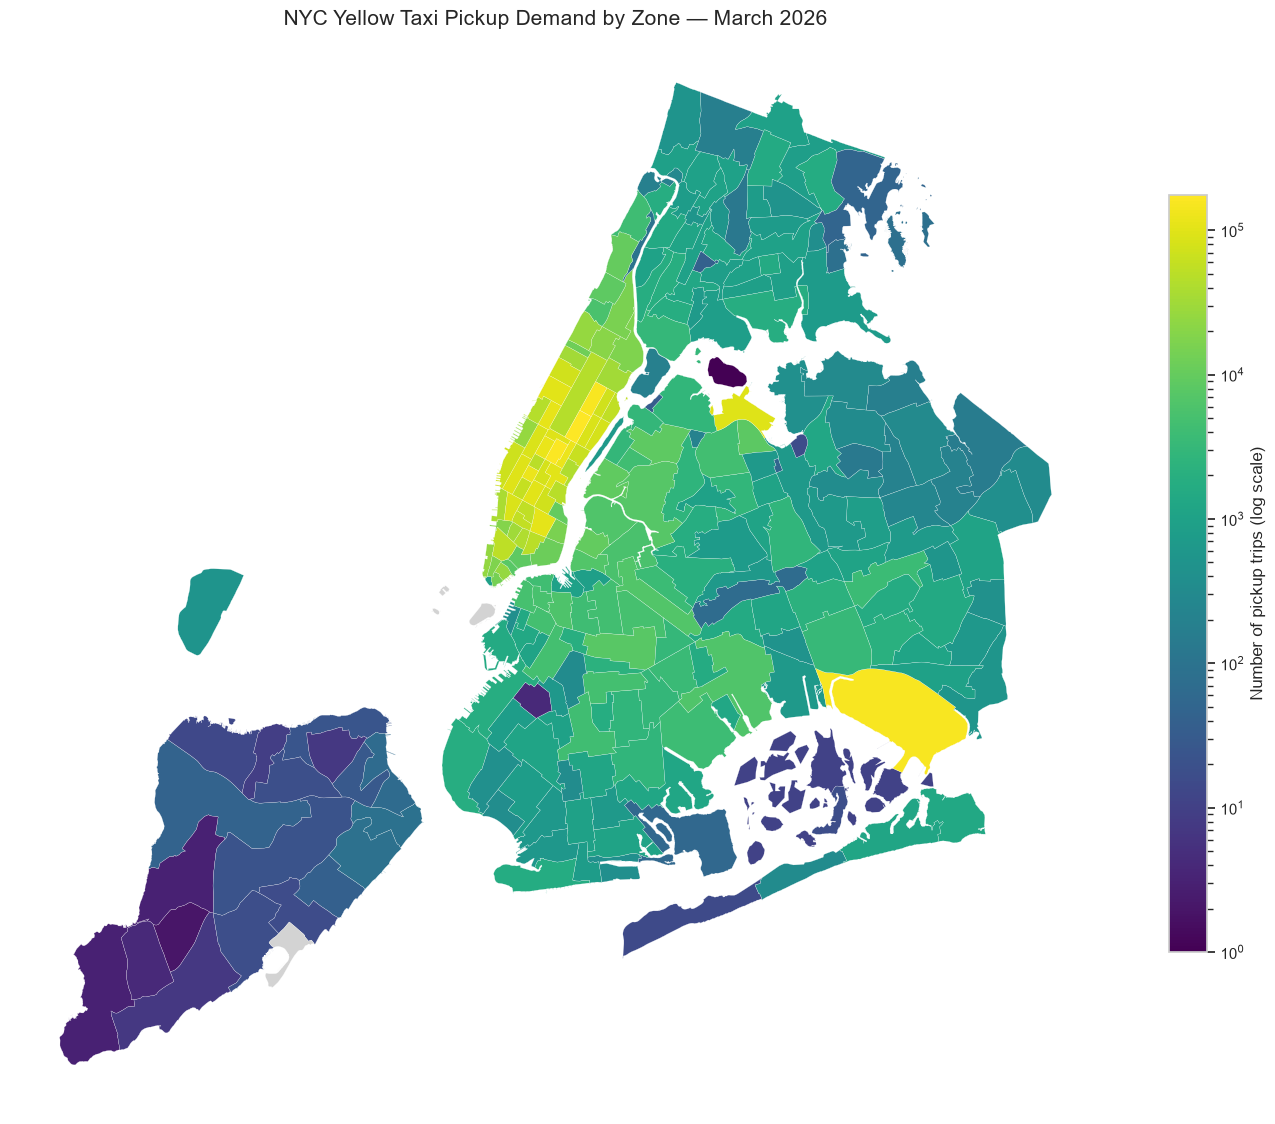

In [53]:
zones_plot = zones_demand.copy()

zones_plot["trip_count_log"] = zones_plot["trip_count"].where(
    zones_plot["trip_count"] > 0
)

fig, ax = plt.subplots(figsize=(14, 12))

zones_plot.plot(
    column="trip_count_log",
    cmap="viridis",
    linewidth=0.15,
    edgecolor="white",
    legend=True,
    norm=LogNorm(
        vmin=1,
        vmax=max(1, zones_plot["trip_count"].max())
    ),
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "white",
        "label": "No recorded pickups"
    },
    legend_kwds={
        "label": "Number of pickup trips (log scale)",
        "shrink": 0.65
    },
    ax=ax
)

ax.set_title(
    "NYC Yellow Taxi Pickup Demand by Zone — March 2026",
    fontsize=15
)
ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "pickup_demand_map_log_march_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
zone_demand_summary = pd.DataFrame({
    "metric": [
        "Number of zones with pickup activity",
        "Total pickup trips",
        "Mean trips per active zone",
        "Median trips per active zone",
        "Maximum trips in one zone",
        "Minimum trips in active zones"
    ],
    "value": [
        pickup_counts["LocationID"].nunique(),
        pickup_counts["trip_count"].sum(),
        pickup_counts["trip_count"].mean(),
        pickup_counts["trip_count"].median(),
        pickup_counts["trip_count"].max(),
        pickup_counts["trip_count"].min()
    ]
})

display(zone_demand_summary)

zone_demand_summary.to_csv(
    TABLES_DIR / "pickup_zone_demand_summary_march_2026.csv",
    index=False
)

,metric,value
0,Number of zones with pickup activity,2.610000e+02
1,Total pickup trips,3.952432e+06
2,Mean trips per active zone,1.514342e+04
3,Median trips per active zone,1.349000e+03
4,Maximum trips in one zone,1.744030e+05
5,Minimum trips in active zones,1.000000e+00


In [55]:
od_counts = (
    df_mar
    .groupby(["PULocationID", "DOLocationID"])
    .size()
    .rename("trip_count")
    .reset_index()
    .rename(columns={
        "PULocationID": "PU_LocationID",
        "DOLocationID": "DO_LocationID"
    })
)

od_counts["share_percent"] = (
    od_counts["trip_count"] / len(df_mar) * 100
)

print("Number of observed OD pairs:", len(od_counts))

display(
    od_counts
    .sort_values("trip_count", ascending=False)
    .head(10)
)

Number of observed OD pairs: 40550


,PU_LocationID,DO_LocationID,trip_count,share_percent
36054,237,236,25028,0.633230
35821,236,237,21479,0.543438
36055,237,237,17324,0.438312
35820,236,236,16923,0.428167
24102,161,237,11414,0.288784
35989,237,161,10339,0.261586
24101,161,236,9669,0.244634
36490,239,238,9057,0.229150
21086,142,239,8885,0.224798
36411,239,142,8747,0.221307


In [56]:
pickup_lookup = zones_lookup[
    ["LocationID", "Zone", "Borough"]
].rename(columns={
    "LocationID": "PU_LocationID",
    "Zone": "PU_Zone",
    "Borough": "PU_Borough"
})

dropoff_lookup = zones_lookup[
    ["LocationID", "Zone", "Borough"]
].rename(columns={
    "LocationID": "DO_LocationID",
    "Zone": "DO_Zone",
    "Borough": "DO_Borough"
})

od_named = (
    od_counts
    .merge(
        pickup_lookup,
        on="PU_LocationID",
        how="left",
        validate="many_to_one"
    )
    .merge(
        dropoff_lookup,
        on="DO_LocationID",
        how="left",
        validate="many_to_one"
    )
)

top_od_pairs = (
    od_named
    .sort_values("trip_count", ascending=False)
    .reset_index(drop=True)
)

top_od_pairs.to_csv(
    TABLES_DIR / "top_od_pairs_march_2026.csv",
    index=False
)

display(
    top_od_pairs[
        [
            "PU_Zone",
            "PU_Borough",
            "DO_Zone",
            "DO_Borough",
            "trip_count",
            "share_percent"
        ]
    ].head(20)
)

,PU_Zone,PU_Borough,DO_Zone,DO_Borough,trip_count,share_percent
0,Upper East Side South,Manhattan,Upper East Side North,Manhattan,25028,0.633230
1,Upper East Side North,Manhattan,Upper East Side South,Manhattan,21479,0.543438
2,Upper East Side South,Manhattan,Upper East Side South,Manhattan,17324,0.438312
3,Upper East Side North,Manhattan,Upper East Side North,Manhattan,16923,0.428167
4,Midtown Center,Manhattan,Upper East Side South,Manhattan,11414,0.288784
5,Upper East Side South,Manhattan,Midtown Center,Manhattan,10339,0.261586
6,Midtown Center,Manhattan,Upper East Side North,Manhattan,9669,0.244634
7,Upper West Side South,Manhattan,Upper West Side North,Manhattan,9057,0.229150
8,Lincoln Square East,Manhattan,Upper West Side South,Manhattan,8885,0.224798
9,Upper West Side South,Manhattan,Lincoln Square East,Manhattan,8747,0.221307


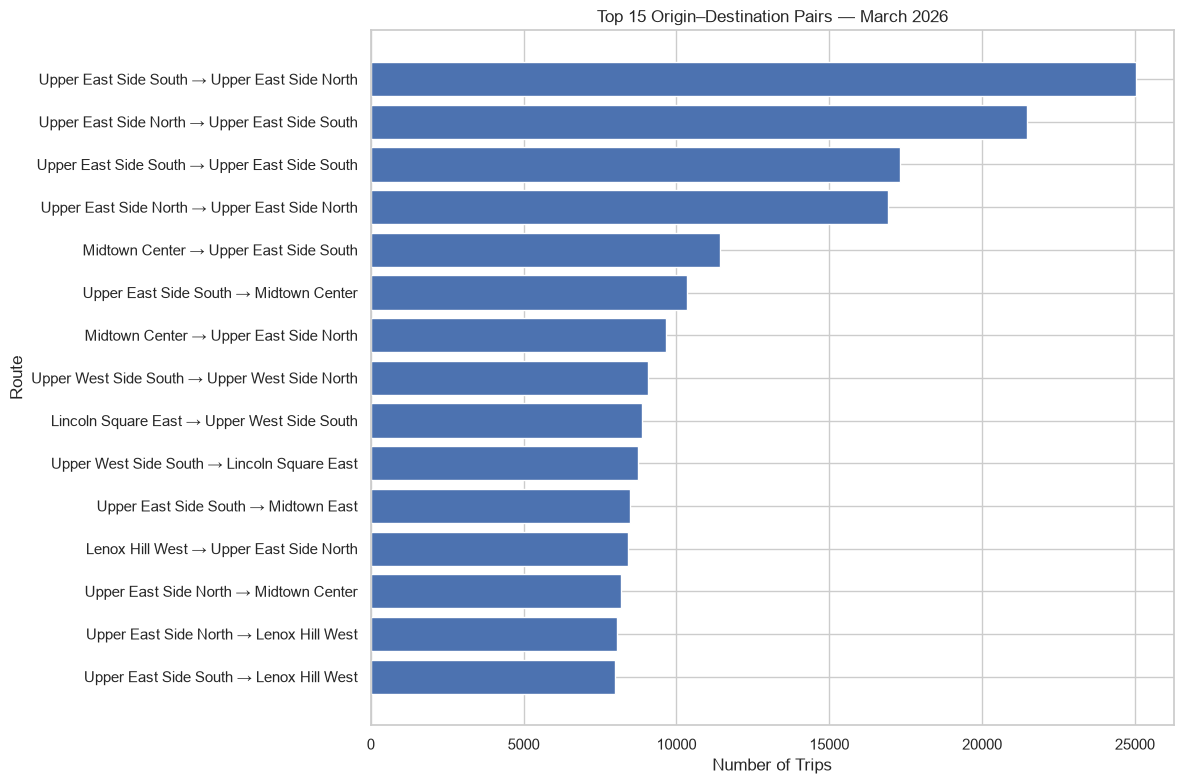

In [57]:
top_15_od = top_od_pairs.head(15).copy()

top_15_od["route"] = (
    top_15_od["PU_Zone"].fillna("Unknown")
    + " → "
    + top_15_od["DO_Zone"].fillna("Unknown")
)

top_15_od = top_15_od.sort_values("trip_count", ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    top_15_od["route"],
    top_15_od["trip_count"]
)

ax.set_title("Top 15 Origin–Destination Pairs — March 2026")
ax.set_xlabel("Number of Trips")
ax.set_ylabel("Route")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_od_pairs_march_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
ts = (
    daily_demand
    .sort_index()
    .astype("float64")
    .asfreq("D")
)

print("Start date:", ts.index.min())
print("End date:", ts.index.max())
print("Number of observations:", len(ts))
print("Missing observations:", ts.isna().sum())

if ts.isna().any():
    raise ValueError(
        "Daily demand contains missing dates or values. "
        "Investigate them before forecasting."
    )

display(ts.to_frame(name="trip_count").head())
display(ts.to_frame(name="trip_count").tail())

Start date: 2026-03-01 00:00:00
End date: 2026-03-31 00:00:00
Number of observations: 31
Missing observations: 0


,trip_count
tpep_pickup_datetime,
2026-03-01,112181.0
2026-03-02,113408.0
2026-03-03,135124.0
2026-03-04,126008.0
2026-03-05,152515.0


,trip_count
tpep_pickup_datetime,
2026-03-27,126695.0
2026-03-28,134101.0
2026-03-29,109562.0
2026-03-30,101370.0
2026-03-31,114554.0


In [59]:
test_size = 7
seasonal_period = 7

if len(ts) <= test_size + seasonal_period:
    raise ValueError(
        "Not enough observations for the selected train-test split."
    )

train = ts.iloc[:-test_size]
test = ts.iloc[-test_size:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Training observations:", len(train))

print("\nTesting period:", test.index.min(), "to", test.index.max())
print("Testing observations:", len(test))

display(
    pd.DataFrame({
        "actual_trips": test
    })
)

Training period: 2026-03-01 00:00:00 to 2026-03-24 00:00:00
Training observations: 24

Testing period: 2026-03-25 00:00:00 to 2026-03-31 00:00:00
Testing observations: 7


,actual_trips
tpep_pickup_datetime,
2026-03-25,121768.0
2026-03-26,128765.0
2026-03-27,126695.0
2026-03-28,134101.0
2026-03-29,109562.0
2026-03-30,101370.0
2026-03-31,114554.0


In [60]:
history = train.tolist()
naive_predictions = []

for actual_value in test:
    prediction = history[-1]
    naive_predictions.append(prediction)

    # After the day is observed, it becomes available for the next prediction.
    history.append(actual_value)

naive_results = pd.DataFrame(
    {
        "actual": test.to_numpy(),
        "predicted": naive_predictions
    },
    index=test.index
)

naive_results["error"] = (
    naive_results["actual"] - naive_results["predicted"]
)

naive_results["absolute_error"] = naive_results["error"].abs()

naive_results["squared_error"] = (
    naive_results["error"] ** 2
)

display(naive_results)

,actual,predicted,error,absolute_error,squared_error
tpep_pickup_datetime,,,,,
2026-03-25,121768.0,119024.0,2744.0,2744.0,7529536.0
2026-03-26,128765.0,121768.0,6997.0,6997.0,48958009.0
2026-03-27,126695.0,128765.0,-2070.0,2070.0,4284900.0
2026-03-28,134101.0,126695.0,7406.0,7406.0,54848836.0
2026-03-29,109562.0,134101.0,-24539.0,24539.0,602162521.0
2026-03-30,101370.0,109562.0,-8192.0,8192.0,67108864.0
2026-03-31,114554.0,101370.0,13184.0,13184.0,173817856.0


In [61]:
seasonal_predictions = ts.shift(seasonal_period).loc[test.index]

seasonal_results = pd.DataFrame(
    {
        "actual": test,
        "predicted": seasonal_predictions
    },
    index=test.index
)

seasonal_results["error"] = (
    seasonal_results["actual"] - seasonal_results["predicted"]
)

seasonal_results["absolute_error"] = (
    seasonal_results["error"].abs()
)

seasonal_results["squared_error"] = (
    seasonal_results["error"] ** 2
)

display(seasonal_results)

,actual,predicted,error,absolute_error,squared_error
tpep_pickup_datetime,,,,,
2026-03-25,121768.0,144364.0,-22596.0,22596.0,510579216.0
2026-03-26,128765.0,149180.0,-20415.0,20415.0,416772225.0
2026-03-27,126695.0,141855.0,-15160.0,15160.0,229825600.0
2026-03-28,134101.0,135560.0,-1459.0,1459.0,2128681.0
2026-03-29,109562.0,116064.0,-6502.0,6502.0,42276004.0
2026-03-30,101370.0,106383.0,-5013.0,5013.0,25130169.0
2026-03-31,114554.0,119024.0,-4470.0,4470.0,19980900.0


In [62]:
def evaluate_forecast(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid_mask = np.isfinite(actual) & np.isfinite(predicted)

    actual = actual[valid_mask]
    predicted = predicted[valid_mask]

    if len(actual) == 0:
        raise ValueError("No valid observations available for evaluation.")

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    return {
        "MAE": mae,
        "RMSE": rmse,
        "n_observations": len(actual)
    }


naive_metrics = evaluate_forecast(
    naive_results["actual"],
    naive_results["predicted"]
)

seasonal_metrics = evaluate_forecast(
    seasonal_results["actual"],
    seasonal_results["predicted"]
)

print("Naive metrics:", naive_metrics)
print("Seasonal Naive metrics:", seasonal_metrics)

Naive metrics: {'MAE': np.float64(9304.57142857143), 'RMSE': np.float64(11702.933222060186), 'n_observations': 7}
Seasonal Naive metrics: {'MAE': np.float64(10802.142857142857), 'RMSE': np.float64(13345.372633024741), 'n_observations': 7}


In [63]:
forecast_comparison = pd.DataFrame(
    [
        {
            "model": "Naive",
            **naive_metrics
        },
        {
            "model": "Seasonal Naive",
            **seasonal_metrics
        }
    ]
)

forecast_comparison = forecast_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

display(
    forecast_comparison.style.format({
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "n_observations": "{:.0f}"
    })
)

forecast_comparison.to_csv(
    TABLES_DIR / "forecast_model_comparison_march_2026.csv",
    index=False
)

,model,MAE,RMSE,n_observations
0,Naive,"9,304.57","11,702.93",7
1,Seasonal Naive,"10,802.14","13,345.37",7


In [64]:
naive_mae = naive_metrics["MAE"]
seasonal_mae = seasonal_metrics["MAE"]

naive_rmse = naive_metrics["RMSE"]
seasonal_rmse = seasonal_metrics["RMSE"]

mae_improvement = (
    (seasonal_mae - naive_mae) / seasonal_mae * 100
    if seasonal_mae != 0
    else np.nan
)

rmse_improvement = (
    (seasonal_rmse - naive_rmse) / seasonal_rmse * 100
    if seasonal_rmse != 0
    else np.nan
)

print(f"Naive MAE improvement over Seasonal Naive: {mae_improvement:.2f}%")
print(f"Naive RMSE improvement over Seasonal Naive: {rmse_improvement:.2f}%")

Naive MAE improvement over Seasonal Naive: 13.86%
Naive RMSE improvement over Seasonal Naive: 12.31%


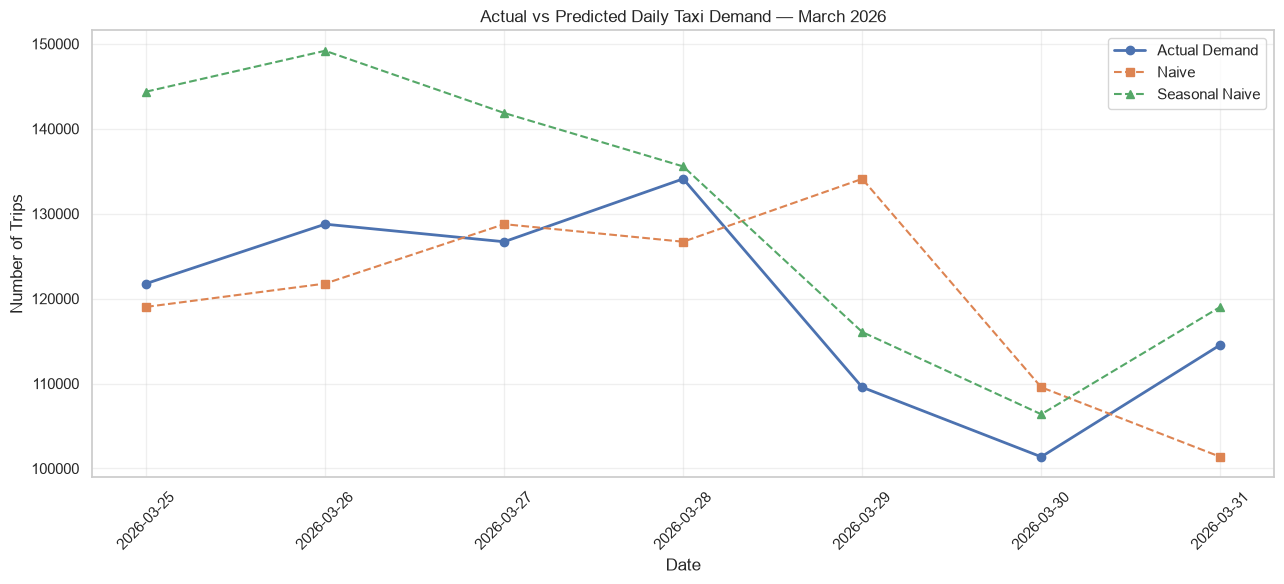

In [65]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    test.index,
    test.values,
    marker="o",
    linewidth=2,
    label="Actual Demand"
)

ax.plot(
    naive_results.index,
    naive_results["predicted"],
    marker="s",
    linestyle="--",
    label="Naive"
)

ax.plot(
    seasonal_results.index,
    seasonal_results["predicted"],
    marker="^",
    linestyle="--",
    label="Seasonal Naive"
)

ax.set_title("Actual vs Predicted Daily Taxi Demand — March 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Trips")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "forecast_comparison_march_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

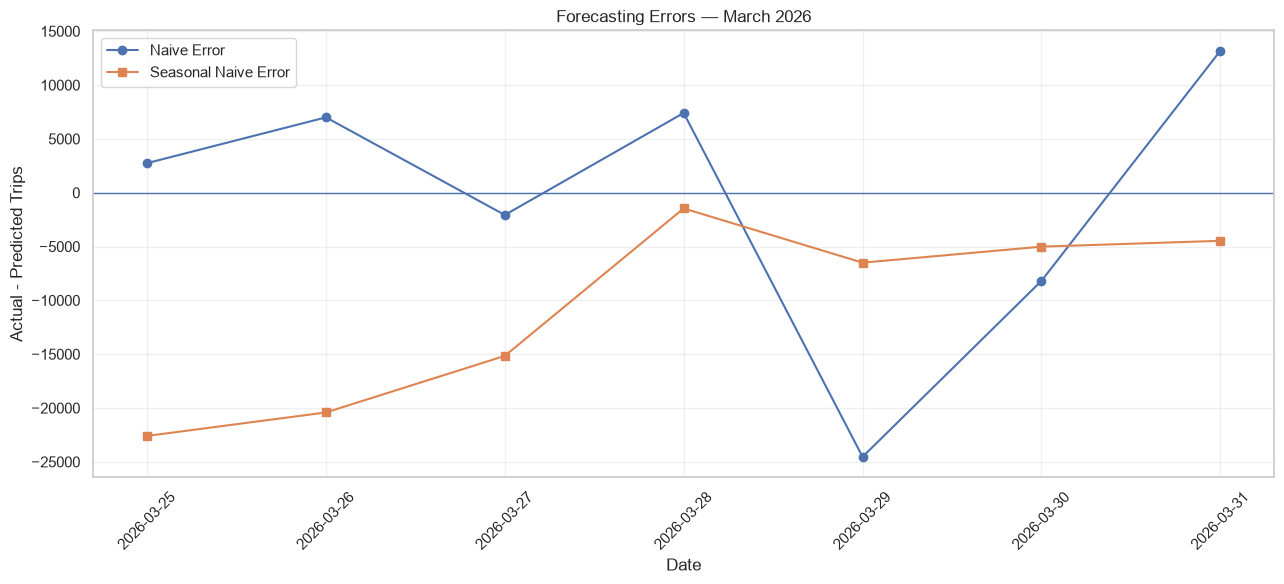

In [66]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.axhline(0, linewidth=1)

ax.plot(
    naive_results.index,
    naive_results["error"],
    marker="o",
    label="Naive Error"
)

ax.plot(
    seasonal_results.index,
    seasonal_results["error"],
    marker="s",
    label="Seasonal Naive Error"
)

ax.set_title("Forecasting Errors — March 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Actual - Predicted Trips")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "forecast_errors_march_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
naive_results.to_csv(
    TABLES_DIR / "naive_forecast_results_march_2026.csv",
    index_label="date"
)

seasonal_results.to_csv(
    TABLES_DIR / "seasonal_naive_forecast_results_march_2026.csv",
    index_label="date"
)

print("Forecasting outputs saved successfully.")

print("\nGenerated files:")
print(TABLES_DIR / "forecast_model_comparison_march_2026.csv")
print(TABLES_DIR / "naive_forecast_results_march_2026.csv")
print(TABLES_DIR / "seasonal_naive_forecast_results_march_2026.csv")
print(FIGURES_DIR / "forecast_comparison_march_2026.png")
print(FIGURES_DIR / "forecast_errors_march_2026.png")

Forecasting outputs saved successfully.

Generated files:
C:\Users\User\Desktop\NYC-TLC-Yellow-Taxi\NYC-TLC-Yellow-Taxi-main\outputs\tables\forecast_model_comparison_march_2026.csv
C:\Users\User\Desktop\NYC-TLC-Yellow-Taxi\NYC-TLC-Yellow-Taxi-main\outputs\tables\naive_forecast_results_march_2026.csv
C:\Users\User\Desktop\NYC-TLC-Yellow-Taxi\NYC-TLC-Yellow-Taxi-main\outputs\tables\seasonal_naive_forecast_results_march_2026.csv
C:\Users\User\Desktop\NYC-TLC-Yellow-Taxi\NYC-TLC-Yellow-Taxi-main\outputs\figures\forecast_comparison_march_2026.png
C:\Users\User\Desktop\NYC-TLC-Yellow-Taxi\NYC-TLC-Yellow-Taxi-main\outputs\figures\forecast_errors_march_2026.png


In [68]:

expected_files = {
    "tables": [
        "raw_dataset_structure.csv",
        "dataset_overview_march_2026.csv",
        "data_dictionary_march_2026.csv",
        "missing_values_march_2026.csv",
        "numeric_descriptive_statistics_march_2026.csv",
        "pearson_correlation_march_2026.csv",
        "spearman_correlation_march_2026.csv",
        "correlation_comparison_march_2026.csv",
        "daily_demand_march_2026.csv",
        "weekday_demand_march_2026.csv",
        "hourly_demand_march_2026.csv",
        "weekday_hour_demand_march_2026.csv",
        "top_pickup_zones_march_2026.csv",
        "pickup_zone_demand_summary_march_2026.csv",
        "top_od_pairs_march_2026.csv",
        "forecast_model_comparison_march_2026.csv",
        "naive_forecast_results_march_2026.csv",
        "seasonal_naive_forecast_results_march_2026.csv",
    ],
    "figures": [
        "numeric_distributions_march_2026.png",
        "passenger_count_distribution_march_2026.png",
        "multivariate_pairplot_march_2026.png",
        "correlation_heatmaps_march_2026.png",
        "daily_demand_march_2026.png",
        "weekday_demand_march_2026.png",
        "hourly_demand_march_2026.png",
        "weekday_hour_demand_march_2026.png",
        "pickup_demand_map_log_march_2026.png",
        "top_od_pairs_march_2026.png",
        "forecast_comparison_march_2026.png",
        "forecast_errors_march_2026.png",
    ],
}

output_check = []

for category, filenames in expected_files.items():
    folder = TABLES_DIR if category == "tables" else FIGURES_DIR

    for filename in filenames:
        file_path = folder / filename

        output_check.append({
            "category": category,
            "filename": filename,
            "exists": file_path.exists(),
            "size_kb": (
                round(file_path.stat().st_size / 1024, 2)
                if file_path.exists()
                else np.nan
            )
        })

output_check = pd.DataFrame(output_check)

display(output_check)

print("\nExisting files:", output_check["exists"].sum())
print("Missing files:", (~output_check["exists"]).sum())

output_check.to_csv(
    TABLES_DIR / "phase_1_output_audit.csv",
    index=False
)

,category,filename,exists,size_kb
0,tables,raw_dataset_structure.csv,True,0.75
1,tables,dataset_overview_march_2026.csv,True,0.30
2,tables,data_dictionary_march_2026.csv,True,0.75
3,tables,missing_values_march_2026.csv,True,0.49
4,tables,numeric_descriptive_statistics_march_2026.csv,True,0.97
5,tables,pearson_correlation_march_2026.csv,True,0.22
6,tables,spearman_correlation_march_2026.csv,True,0.22
7,tables,correlation_comparison_march_2026.csv,True,0.24
8,tables,daily_demand_march_2026.csv,True,0.59
9,tables,weekday_demand_march_2026.csv,True,0.46



Existing files: 30
Missing files: 0


In [69]:
# Cell 68: Final validation of date range and daily demand

pickup_dates = df_mar["tpep_pickup_datetime"]

validation_results = {
    "expected_start_date": START_DATE,
    "expected_end_date_exclusive": END_DATE,
    "observed_min_pickup": pickup_dates.min(),
    "observed_max_pickup": pickup_dates.max(),
    "rows_in_march": len(df_mar),
    "rows_outside_march": int(
        (
            (pickup_dates < START_DATE)
            | (pickup_dates >= END_DATE)
        ).sum()
    ),
    "daily_series_observations": len(ts),
    "daily_series_missing_values": int(ts.isna().sum()),
    "daily_series_total_trips": int(ts.sum()),
    "filtered_dataframe_total_trips": len(df_mar),
}

validation_table = pd.DataFrame(
    list(validation_results.items()),
    columns=["check", "value"]
)

display(validation_table)

assert validation_results["rows_outside_march"] == 0, (
    "Some pickup timestamps fall outside March 2026."
)

assert validation_results["daily_series_missing_values"] == 0, (
    "The daily time series contains missing values."
)

assert validation_results["daily_series_total_trips"] == len(df_mar), (
    "Daily demand total does not match the number of filtered trips."
)

validation_table.to_csv(
    TABLES_DIR / "phase_1_validation_results.csv",
    index=False
)

print("Final validation completed successfully.")

,check,value
0,expected_start_date,2026-03-01 00:00:00
1,expected_end_date_exclusive,2026-04-01 00:00:00
2,observed_min_pickup,2026-03-01 00:00:00
3,observed_max_pickup,2026-03-31 23:59:59
4,rows_in_march,3952432
5,rows_outside_march,0
6,daily_series_observations,31
7,daily_series_missing_values,0
8,daily_series_total_trips,3952432
9,filtered_dataframe_total_trips,3952432


Final validation completed successfully.


In [70]:
top_pickup = top_pickup_zones.iloc[0]
top_route = top_od_pairs.iloc[0]

best_model = forecast_comparison.iloc[0]

findings = [
    {
        "topic": "Dataset",
        "finding": (
            f"The March 2026 dataset contains {len(df_mar):,} trips."
        )
    },
    {
        "topic": "Data Quality",
        "finding": (
            f"{int(df_mar.duplicated().sum()):,} exact duplicate rows "
            "were identified in the filtered dataset."
        )
    },
    {
        "topic": "Trip Characteristics",
        "finding": (
            f"Median trip distance is "
            f"{df_mar['trip_distance'].median():.2f} miles."
        )
    },
    {
        "topic": "Trip Characteristics",
        "finding": (
            f"Median trip duration is "
            f"{df_mar['trip_duration_min'].median():.2f} minutes."
        )
    },
    {
        "topic": "Geography",
        "finding": (
            f"The highest-volume pickup zone is {top_pickup['Zone']} "
            f"({top_pickup['Borough']}), with "
            f"{int(top_pickup['trip_count']):,} trips."
        )
    },
    {
        "topic": "Geography",
        "finding": (
            f"The most frequent observed OD pair is "
            f"{top_route['PU_Zone']} to {top_route['DO_Zone']}, "
            f"with {int(top_route['trip_count']):,} trips."
        )
    },
    {
        "topic": "Forecasting",
        "finding": (
            f"The lowest MAE among the evaluated baseline models "
            f"was obtained by {best_model['model']}, with "
            f"MAE={best_model['MAE']:.2f} and "
            f"RMSE={best_model['RMSE']:.2f}."
        )
    },
    {
        "topic": "Limitations",
        "finding": (
            "Forecast evaluation uses only the final seven days of "
            "one month; results should be treated as preliminary."
        )
    },
]

findings_df = pd.DataFrame(findings)

display(findings_df)

findings_df.to_csv(
    TABLES_DIR / "phase_1_findings_summary.csv",
    index=False
)

,topic,finding
0,Dataset,"The March 2026 dataset contains 3,952,432 trips."
1,Data Quality,0 exact duplicate rows were identified in the ...
2,Trip Characteristics,Median trip distance is 1.82 miles.
3,Trip Characteristics,Median trip duration is 13.28 minutes.
4,Geography,The highest-volume pickup zone is Upper East S...
5,Geography,The most frequent observed OD pair is Upper Ea...
6,Forecasting,The lowest MAE among the evaluated baseline mo...
7,Limitations,Forecast evaluation uses only the final seven ...
